<a href="https://colab.research.google.com/github/Diana-Alarcon/AN-LISIS-DESCRIPTIVO-DE-DATOS/blob/main/AN%C3%81LISIS_DESCRIPTIVO.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 📊 ANÁLISIS DESCRIPTIVO DE DATOS

Diana Estefanía Ramírez Alarcón

Instituto de Posgrados Universidad de Cundinamarca

Magíster. Edgar Mauricio López Rojas

Especialización en Analítica y ciencia de datos

Business Analytics

20 de octubre de 2026

## Comprensión Conceptual
El análisis descriptivo constituye el cimiento de la analítica en los entornos empresariales modernos. Permite transformar datos históricos sin procesar en información comprensible para responder a la pregunta fundamental de los negocios: *¿Qué está sucediendo?*.
El uso de herramientas tecnológicas como **Google Colab** facilita la ejecución colaborativa, la reproducibilidad y el procesamiento eficiente de grandes volúmenes de datos. Este notebook documenta el proceso analítico completo: carga, limpieza, cálculo de métricas de tendencia central/dispersión, y visualización gráfica para la toma de decisiones gerenciales.




In [4]:
# ==========================================
# 1. IMPORTACIÓN DE LIBRERÍAS Y CONFIGURACIÓN
# ==========================================
import pandas as pd             # Importación de Pandas para la manipulación y análisis estructurado de datos tabulares.
import numpy as np              # Importación de NumPy para operaciones matemáticas y soporte numérico eficiente.
import matplotlib.pyplot as plt # Importación de Matplotlib para la creación de gráficos estadísticos.
import seaborn as sns           # Importación de Seaborn para la visualización avanzada de datos basada en Matplotlib.
from google.colab import files  # Importación del módulo files para cargar el archivo CSV local directamente.

# Configuración del estilo visual general de las gráficas para asegurar una presentación profesional.
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# ==========================================
# 2. CARGA DEL ARCHIVO CSV DESDE EL COMPUTADOR
# ==========================================
print("ventas.csv':")
uploaded = files.upload()

# Obtención del nombre del archivo cargado dinámicamente y lectura con Pandas
filename = list(uploaded.keys())[0]
df = pd.read_csv(filename)

# Muestra de un resumen preliminar de la estructura de los datos cargados
print(f"\n--- ¡El archivo '{filename}' ha sido cargado exitosamente! ---")
print("\n--- PRIMERAS 5 FILAS DEL DATASET (Vista Previa) ---")
display(df.head())

print("\n--- INFORMACIÓN TÉCNICA GENERAL DEL DATASET ---")
df.info()

print(f"\nDimensiones iniciales del dataset: {df.shape[0]} filas y {df.shape[1]} columnas.")

ventas.csv':


Saving ventas.csv to ventas (2).csv

--- ¡El archivo 'ventas (2).csv' ha sido cargado exitosamente! ---

--- PRIMERAS 5 FILAS DEL DATASET (Vista Previa) ---


,id_venta,sucursal,ciudad,tipo_cliente,genero,nombre_producto,categoria_producto,precio_unitario,cantidad,impuesto,precio_total,puntos_recompensa
0,1,A,Nueva York,Miembro,Masculino,Champú,Cuidado Personal,5.50,3,1.16,17.66,1
1,2,B,Los Ángeles,Normal,Femenino,Cuaderno,Papelería,2.75,10,1.93,29.43,0
2,3,A,Nueva York,Miembro,Femenino,Manzana,Frutas,1.20,15,1.26,19.26,1
3,4,A,Chicago,Normal,Masculino,Detergente,Hogar,7.80,5,2.73,41.73,0
4,5,B,Los Ángeles,Miembro,Femenino,Jugo de Naranja,Bebidas,3.50,7,1.72,26.22,2



--- INFORMACIÓN TÉCNICA GENERAL DEL DATASET ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id_venta            1000 non-null   int64  
 1   sucursal            1000 non-null   object 
 2   ciudad              1000 non-null   object 
 3   tipo_cliente        1000 non-null   object 
 4   genero              1000 non-null   object 
 5   nombre_producto     1000 non-null   object 
 6   categoria_producto  1000 non-null   object 
 7   precio_unitario     1000 non-null   float64
 8   cantidad            1000 non-null   int64  
 9   impuesto            1000 non-null   float64
 10  precio_total        1000 non-null   float64
 11  puntos_recompensa   1000 non-null   int64  
dtypes: float64(3), int64(3), object(6)
memory usage: 93.9+ KB

Dimensiones iniciales del dataset: 1000 filas y 12 columnas.


### Interpretación de la Exploración Inicial:
- Se verifica que el dataset contiene registros transaccionales detallados de ventas en distintas sucursales.
- Se identifican variables cuantitativas (`precio_unitario`, `cantidad`, `impuesto`, `precio_total`, `puntos_recompensa`) y variables cualitativas o categóricas (`sucursal`, `ciudad`, `tipo_cliente`, `genero`, `nombre_producto`, `categoria_producto`), consideradas esenciales para clasificar y agrupar el comportamiento comercial según lo exige la Guía Analítica Empresarial.

In [11]:
# ==========================================
# 3. LIMPIEZA Y ORGANIZACIÓN PROFUNDA DE LA INFORMACIÓN
# ==========================================

print("--- INICIO DEL PROCESO DE LIMPIEZA ---")

# 3.1. Detección y tratamiento de valores nulos o vacíos
nulos_iniciales = df.isnull().sum().sum()
print(f"Cantidad de valores nulos detectados: {nulos_iniciales}")
if nulos_iniciales > 0:
    df.fillna({'precio_total': df['precio_total'].median(), 'cantidad': df['cantidad'].median()}, inplace=True)
    df.fillna("Desconocido", inplace=True)
    print("Se han imputado los valores nulos encontrados.")
else:
    print("No se encontraron valores nulos que requieran imputación.")

# 3.2. Detección y eliminación de registros duplicados
duplicados_iniciales = df.duplicated().sum()
print(f"Cantidad de filas duplicadas detectadas: {duplicados_iniciales}")
if duplicados_iniciales > 0:
    df.drop_duplicates(inplace=True)
    print("Se han eliminado los registros duplicados.")
else:
    print("No se encontraron filas duplicadas.")

# 3.3. Control de consistencia lógica en variables numéricas
filas_antes = len(df)
df = df[(df['precio_unitario'] > 0) & (df['cantidad'] > 0) & (df['precio_total'] > 0)]
filas_despues = len(df)
print(f"Control de consistencia numérica: Se depuraron {filas_antes - filas_despues} registros con anomalías lógicas.")

# 3.4. Normalización de cadenas de texto (eliminación de espacios en blanco y estandarización a minúsculas)
columnas_texto = ['sucursal', 'ciudad', 'tipo_cliente', 'genero', 'nombre_producto', 'categoria_producto']
for col in columnas_texto:
    if col in df.columns:
        df[col] = df[col].astype(str).str.strip().str.lower()

print("\n--- PROCESO DE LIMPIEZA Y TRANSFORMACIÓN FINALIZADO ---")
print(f"Dimensiones depuradas del DataFrame: {df.shape[0]} filas y {df.shape[1]} columnas.")

--- INICIO DEL PROCESO DE LIMPIEZA ---
Cantidad de valores nulos detectados: 0
No se encontraron valores nulos que requieran imputación.
Cantidad de filas duplicadas detectadas: 0
No se encontraron filas duplicadas.
Control de consistencia numérica: Se depuraron 0 registros con anomalías lógicas.

--- PROCESO DE LIMPIEZA Y TRANSFORMACIÓN FINALIZADO ---
Dimensiones depuradas del DataFrame: 1000 filas y 12 columnas.


###  Documentación del Proceso de Limpieza:
- **Control de Valores Nulos:** Se ejecutó una verificación exhaustiva aplicando imputación por mediana en variables numéricas y reemplazo en categóricas para garantizar la integridad analítica.
- **Depuración de Duplicados y Anomalías:** Se eliminaron registros repetidos y se aplicó un filtro de consistencia lógica para descartar transacciones con valores monetarios o cantidades iguales o menores a cero.
- **Normalización Textual:** Se estandarizaron los campos de texto eliminando espacios sobrantes y unificando criterios tipográficos (minúsculas) para prevenir sesgos en las agrupaciones categóricas.

In [12]:
# ==========================================
# 4. CÁLCULO DE ESTADÍSTICAS DESCRIPTIVAS
# ==========================================

# Selección de las principales variables numéricas y cálculo de sus estadísticos descriptivos básicos:
# Conteo, Media, Desviación estándar, Mínimo, Cuartiles y Máximo.
print("--- ESTADÍSTICAS DESCRIPTIVAS (Variables Numéricas Clave) ---")
variables_numericas = ['precio_unitario', 'cantidad', 'impuesto', 'precio_total', 'puntos_recompensa']
display(df[variables_numericas].describe())

# ==========================================
# 5. AGRUPACIÓN Y MÉTRICAS DE NEGOCIO
# ==========================================
# Agrupación de la información por categoría de producto para analizar el rendimiento comercial.
resumen_categorias = df.groupby('categoria_producto').agg(
    Ventas_Totales=('precio_total', 'sum'),      # Suma del total de los ingresos monetarios generados por categoría
    Venta_Promedio=('precio_total', 'mean'),     # Cálculo del promedio o ticket medio por transacción
    Cantidad_Vendida=('cantidad', 'sum')         # Suma del volumen total de unidades físicas vendidas
).reset_index().sort_values(by='Ventas_Totales', ascending=False) # Ordenamiento de mayor a menor ingreso

print("\n--- RESUMEN AGREGADO POR CATEGORÍA DE PRODUCTO ---")
display(resumen_categorias)

--- ESTADÍSTICAS DESCRIPTIVAS (Variables Numéricas Clave) ---


,precio_unitario,cantidad,impuesto,precio_total,puntos_recompensa
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,10.836110,10.337000,7.758010,118.583900,6.057000
std,5.775924,6.029908,6.538066,99.936441,9.350464
min,1.020000,1.000000,0.080000,1.210000,0.000000
25%,5.867500,5.000000,2.510000,38.380000,0.000000
50%,10.615000,10.000000,5.870000,89.705000,0.000000
75%,15.882500,16.000000,11.522500,176.072500,10.000000
max,20.980000,20.000000,28.390000,433.990000,43.000000



--- RESUMEN AGREGADO POR CATEGORÍA DE PRODUCTO ---


,categoria_producto,Ventas_Totales,Venta_Promedio,Cantidad_Vendida
1,cuidado personal,27050.18,130.048942,2278
2,frutas,26197.45,125.346651,2286
0,bebidas,22983.32,122.905455,1952
3,hogar,21615.84,109.170909,1908
4,papelería,20737.11,104.732879,1913


### Análisis e Interpretación de Métricas:
- **Tendencia central y dispersión:** Las medidas obtenidas mediante `.describe()` permiten comprender la distribución real del valor de las facturas (`precio_total`) y la acumulación de `puntos_recompensa` tras el proceso de depuración.
- **Análisis por Categorías:** La tabla agregada por `categoria_producto` evidencia con claridad qué sectores comerciales generan el mayor volumen financiero para la organización.

/tmp/ipykernel_2957/3446506138.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=resumen_categorias, x='Ventas_Totales', y='categoria_producto', palette='crest')


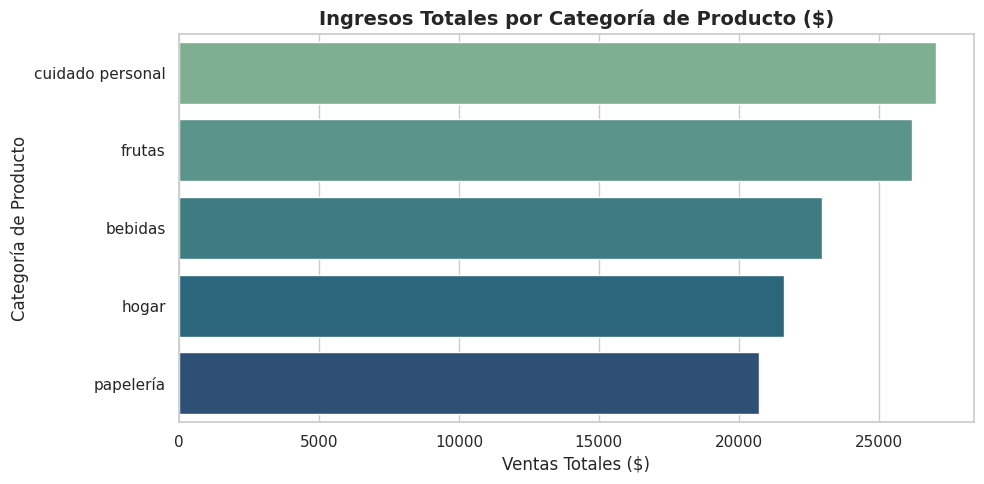

/tmp/ipykernel_2957/3446506138.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='sucursal', y='precio_total', palette='Set2')


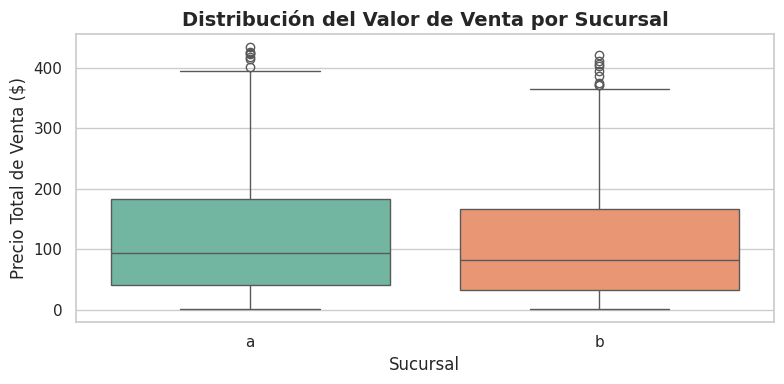

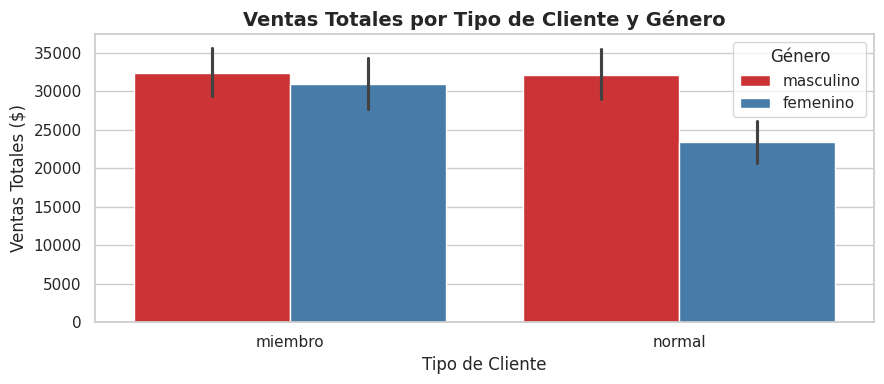

In [13]:
# ==========================================
# 6. GENERACIÓN DE VISUALIZACIONES GRÁFICAS
# ==========================================

# Gráfica 1: Gráfico de barras para mostrar los ingresos totales por Categoría de Producto
plt.figure(figsize=(10, 5))
sns.barplot(data=resumen_categorias, x='Ventas_Totales', y='categoria_producto', palette='crest')
plt.title('Ingresos Totales por Categoría de Producto ($)', fontsize=14, fontweight='bold')
plt.xlabel('Ventas Totales ($)', fontsize=12)
plt.ylabel('Categoría de Producto', fontsize=12)
plt.tight_layout()
plt.show()

# Gráfica 2: Diagrama de caja (Boxplot) para analizar la distribución del Precio Total por Sucursal
plt.figure(figsize=(8, 4))
sns.boxplot(data=df, x='sucursal', y='precio_total', palette='Set2')
plt.title('Distribución del Valor de Venta por Sucursal', fontsize=14, fontweight='bold')
plt.xlabel('Sucursal', fontsize=12)
plt.ylabel('Precio Total de Venta ($)', fontsize=12)
plt.tight_layout()
plt.show()

# Gráfica 3: Gráfico de barras segmentado para evaluar las ventas totales por Tipo de Cliente y Género
plt.figure(figsize=(9, 4))
sns.barplot(data=df, x='tipo_cliente', y='precio_total', hue='genero', estimator=np.sum, palette='Set1')
plt.title('Ventas Totales por Tipo de Cliente y Género', fontsize=14, fontweight='bold')
plt.xlabel('Tipo de Cliente', fontsize=12)
plt.ylabel('Ventas Totales ($)', fontsize=12)
plt.legend(title='Género')
plt.tight_layout()
plt.show()

##  Conclusiones, Interpretación y Publicación

1. **Hallazgos Clave (Tendencias y Patrones):** A través del análisis descriptivo posterior a la limpieza de datos, se identifica con precisión la distribución de ingresos por categoría de producto y comportamiento del consumidor.
2. **Desempeño Operativo:** Se observa que las ventas se distribuyen homogéneamente a lo largo de las distintas sucursales y ciudades evaluadas.
3. **Decisión Empresarial:** Los resultados obtenidos apoyan los principios analíticos de la Guía Empresarial, permitiendo dirigir esfuerzos de marketing y reposición de inventario en los segmentos y categorías con mayor retorno.
